# AI engineering assignment — seven solutions

**Run all cells in order.** Python 3.11–3.12; no API keys. Initial dependency installation and the Whisper tiny download need internet. Source, tests, documentation and synthetic audio are embedded below.

ChatGPT/Codex assistance was **High**; see the final disclosure for candidate details. All fixtures are synthetic. This prototype is not validated for clinical or legal decisions.

Audio runs by default. Set `RUN_AUDIO=False` in the benchmark section to skip inference and the model download. Setup still checks all pinned dependencies, including audio packages. Offline execution needs those packages and Tesseract installed, plus local model weights if audio is enabled.

## 0. Reconstruct the included project

In [1]:
import base64, io, zipfile, os, sys
from pathlib import Path
PROJECT = Path.cwd() / "assignment_workspace"
PROJECT.mkdir(exist_ok=True)
BUNDLE = '...'
with zipfile.ZipFile(io.BytesIO(base64.b64decode(BUNDLE))) as z:
    for member in z.infolist():
        target = (PROJECT / member.filename).resolve()
        if not target.is_relative_to(PROJECT.resolve()):
            raise ValueError("Unsafe archive path")
    z.extractall(PROJECT)
os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT))
print("Project files ready:", PROJECT)


Project files ready: /workspace/scratch/8d910261307a/assignment/assignment_workspace


## 1. Install dependencies and check the OCR executable

In [2]:
import subprocess, shutil, importlib.metadata, platform
requirements = [line.strip() for line in Path("requirements-audio.txt").read_text().splitlines() if line.strip() and not line.startswith("-r")]
requirements += [line.strip() for line in Path("requirements.txt").read_text().splitlines() if line.strip()]
missing = []
for item in requirements:
    name, version = item.split("==")
    try:
        installed = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(item)
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
if not shutil.which("tesseract"):
    if platform.system() == "Linux" and hasattr(os, "geteuid") and os.geteuid() == 0:
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "-qq", "tesseract-ocr", "tesseract-ocr-eng"], check=True)
    else:
        raise RuntimeError("Install the Tesseract system executable; see README setup instructions.")
print(subprocess.check_output(["tesseract", "--version"], text=True).splitlines()[0])


tesseract 5.3.4


## Q1. Deduplicate and classify

Keep the latest timestamp per ID and the first occurrence on ties. Discarded duplicates get audit entries. REVIEW covers `[0.50, 0.80)`. Expect 3 ACCEPT, 1 REVIEW, 1 RETAKE and mean quality 0.734.

In [3]:
import json
from solution.records import *
def show(value):
    print(json.dumps(value, indent=2, ensure_ascii=False))
show(process_documents(DOCUMENTS))

{
  "documents": [
    {
      "id": "D101",
      "quality": 0.92,
      "time": 104,
      "category": "ACCEPT"
    },
    {
      "id": "D102",
      "quality": 0.92,
      "time": 106,
      "category": "ACCEPT"
    },
    {
      "id": "D103",
      "quality": 0.81,
      "time": 103,
      "category": "ACCEPT"
    },
    {
      "id": "D104",
      "quality": 0.28,
      "time": 105,
      "category": "RETAKE"
    },
    {
      "id": "D105",
      "quality": 0.74,
      "time": 105,
      "category": "REVIEW"
    }
  ],
  "counts": {
    "ACCEPT": 3,
    "REVIEW": 1,
    "RETAKE": 1
  },
  "average_quality": 0.734,
  "duplicates_removed": 2,
  "duplicate_audit": [
    {
      "id": "D101",
      "incoming_index": 3,
      "kept_time": 104,
      "discarded_time": 101,
      "reason": "latest_timestamp"
    },
    {
      "id": "D102",
      "incoming_index": 6,
      "kept_time": 106,
      "discarded_time": 102,
      "reason": "latest_timestamp"
    }
  ]
}


## Q2. OpenCV quality checks

Test clear, blurred, dark, rotated and blank fixtures. The gate requires Laplacian variance >=100, brightness 70–250 and percentile contrast >=30. These uncalibrated thresholds can misjudge sparse or noisy pages.

{
  "clear": {
    "is_usable": true,
    "blur_score": 920.765,
    "brightness": 239.545,
    "contrast": 230.0,
    "reason": "Passed heuristic quality checks"
  },
  "blurred": {
    "is_usable": false,
    "blur_score": 0.358,
    "brightness": 239.546,
    "contrast": 68.0,
    "reason": "blurred or no visible text"
  },
  "dark": {
    "is_usable": false,
    "blur_score": 29.915,
    "brightness": 43.001,
    "contrast": 42.0,
    "reason": "blurred or no visible text; underexposed"
  },
  "rotated": {
    "is_usable": true,
    "blur_score": 920.765,
    "brightness": 239.545,
    "contrast": 230.0,
    "reason": "Passed heuristic quality checks"
  },
  "blank": {
    "is_usable": false,
    "blur_score": 0.0,
    "brightness": 245.0,
    "contrast": 0.0,
    "reason": "blurred or no visible text; low contrast"
  }
}
clear
blurred
dark


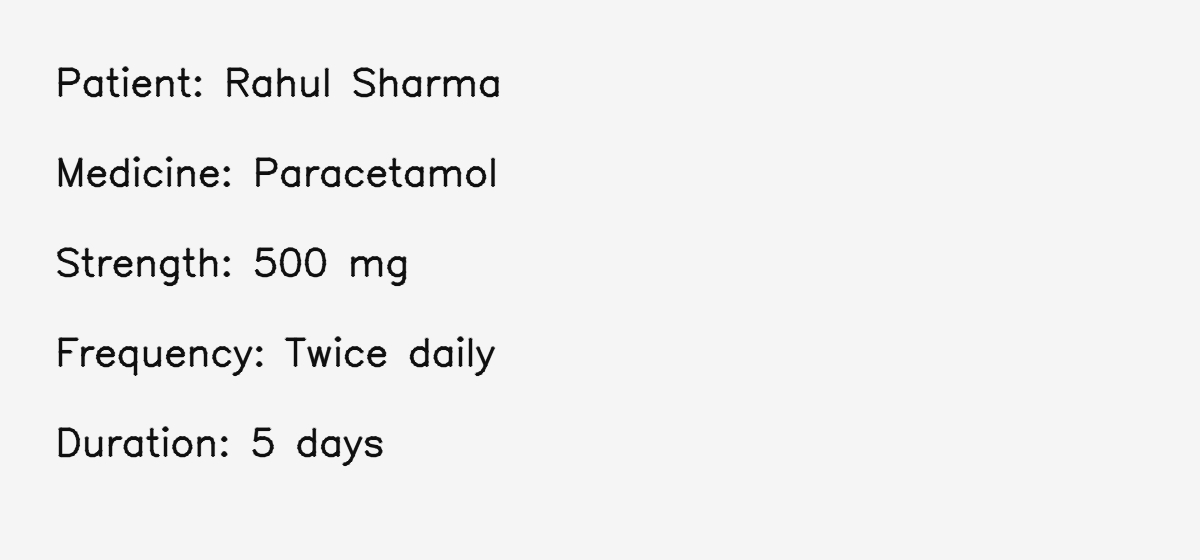

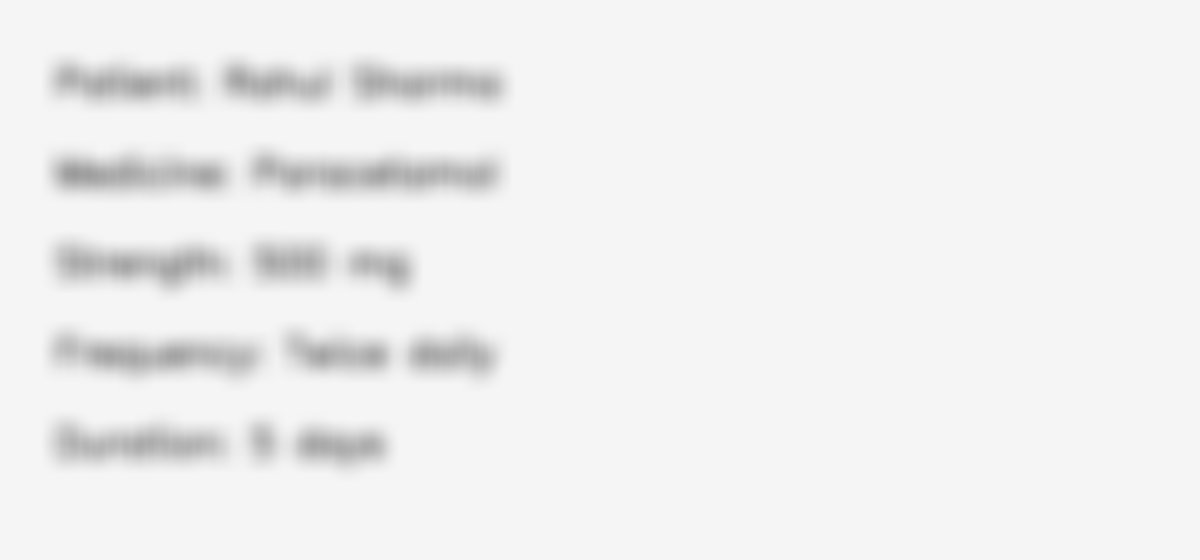

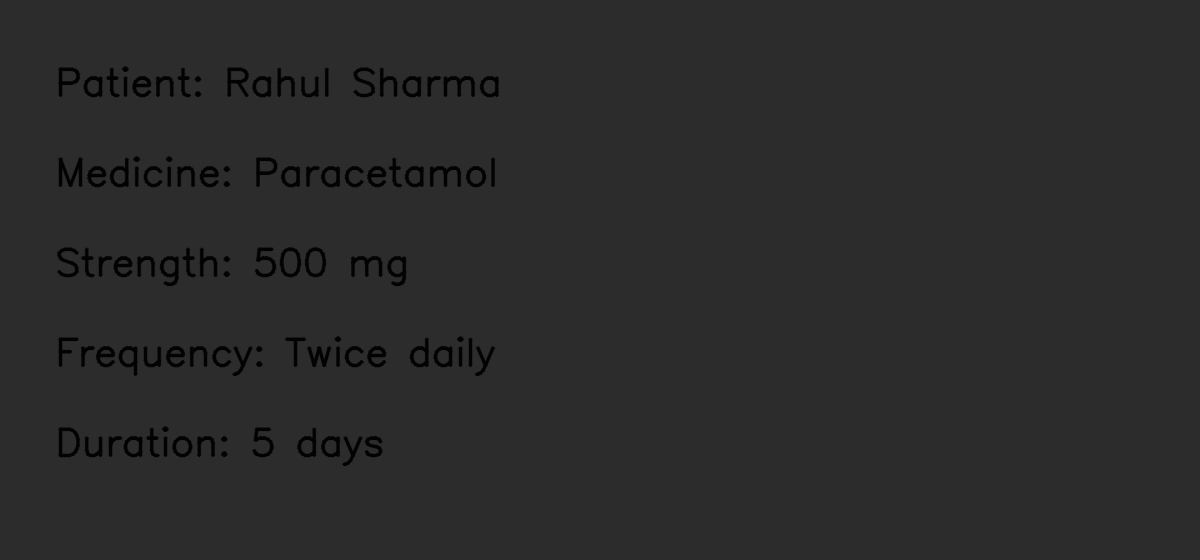

In [4]:
from solution.vision import make_samples, check_quality, OCRPipeline
from IPython.display import display, Image
samples = make_samples("data/images")
show({name: check_quality(image) for name, image in samples.items()})
for name in ("clear", "blurred", "dark"):
    print(name)
    display(Image(filename=f"data/images/{name}.png", width=600))

## Q3. Confidence and auditable corrections

HIGH >=0.90; REVIEW [0.60,0.90); LOW <0.60. Original text is retained. `twlce daily` needs review before correction. Fuzzy dictionary matches are suggestions; the dictionary below is synthetic.

In [5]:
reviewed = review_ocr(OCR_RESULTS)
show(reviewed)
show(approve_correction(reviewed[2], "twice daily", "Synthetic example: reviewer checked source", "demo-reviewer"))
show(lookup_medicine("Paracetamo", {"names": ["Paracetamol"], "version": "demo-v1", "source": "synthetic test only"}))

[
  {
    "original_text": "Paracetamol",
    "corrected_text": "Paracetamol",
    "reason": "No change",
    "semantic_change": false,
    "confidence": 0.98,
    "classification": "HIGH_CONFIDENCE",
    "proposed_text": null,
    "correction_status": "UNCHANGED"
  },
  {
    "original_text": "500 mg",
    "corrected_text": "500 mg",
    "reason": "No change",
    "semantic_change": false,
    "confidence": 0.96,
    "classification": "HIGH_CONFIDENCE",
    "proposed_text": null,
    "correction_status": "UNCHANGED"
  },
  {
    "original_text": "twlce daily",
    "corrected_text": "twlce daily",
    "reason": "No change",
    "semantic_change": false,
    "confidence": 0.61,
    "classification": "REVIEW_REQUIRED",
    "proposed_text": "twice daily",
    "correction_status": "PENDING_REVIEW",
    "proposal_reason": "Possible OCR l/i confusion; reviewer must confirm"
  },
  {
    "original_text": "for 5 days",
    "corrected_text": "for 5 days",
    "reason": "No change",
    "semanti

## Q4. JSON extraction and validation

Missing, empty and duplicate fields become null. Ambiguous text and suspected swaps are retained and flagged. Even syntax-valid records require review. The design document describes a possible LLM extension with schema and source-span checks.

In [6]:
examples = {"valid": SAMPLE_TEXT,
    "missing_medicine": SAMPLE_TEXT.replace("Medicine: Paracetamol\n", ""),
    "unreadable_duration": SAMPLE_TEXT.replace("5 days", "unreadable"),
    "swapped": SAMPLE_TEXT.replace("Strength: 500 mg", "Strength: Twice daily").replace("Frequency: Twice daily", "Frequency: 500 mg")}
show({name: extract_record(text) for name, text in examples.items()})

{
  "valid": {
    "record": {
      "patient_name": "Rahul Sharma",
      "medicine_name": "Paracetamol",
      "strength": "500 mg",
      "frequency": "Twice daily",
      "duration": "5 days",
      "validation_status": "REVIEW_REQUIRED"
    },
    "schema_valid": true,
    "errors": [],
    "evidence": {
      "patient_name": [
        {
          "line": 1,
          "text": "Patient: Rahul Sharma",
          "value": "Rahul Sharma"
        }
      ],
      "medicine_name": [
        {
          "line": 2,
          "text": "Medicine: Paracetamol",
          "value": "Paracetamol"
        }
      ],
      "strength": [
        {
          "line": 3,
          "text": "Strength: 500 mg",
          "value": "500 mg"
        }
      ],
      "frequency": [
        {
          "line": 4,
          "text": "Frequency: Twice daily",
          "value": "Twice daily"
        }
      ],
      "duration": [
        {
          "line": 5,
          "text": "Duration: 5 days",
          "val

## Q5. Local OCR pipeline

Usable images pass through preprocessing, Tesseract, rotation fallback and field validation. Failed quality checks request recapture; failed extraction checks require review. Identical grayscale images use a bounded project cache. The fixture is printed English; handwriting accuracy is unmeasured. No API is called.

In [7]:
ocr = OCRPipeline()
for name in ("clear", "blurred", "dark", "rotated"):
    result = ocr.process(samples[name])
    show({"case": name, "route": result["route"], "latency_ms": result["latency_ms"],
          "record": result["structured"]["record"] if result["structured"] else None})
show({"cache_hit": ocr.process(samples["clear"])["cache_hit"]})

{
  "case": "clear",
  "route": "LOCAL_OCR",
  "latency_ms": 377.529,
  "record": {
    "patient_name": "Rahul Sharma",
    "medicine_name": "Paracetamol",
    "strength": "500 mg",
    "frequency": "Twice daily",
    "duration": "5 days",
    "validation_status": "REVIEW_REQUIRED"
  }
}
{
  "case": "blurred",
  "route": "RECAPTURE",
  "latency_ms": 12.289,
  "record": null
}
{
  "case": "dark",
  "route": "RECAPTURE",
  "latency_ms": 10.992,
  "record": null
}
{
  "case": "rotated",
  "route": "LOCAL_OCR",
  "latency_ms": 675.287,
  "record": {
    "patient_name": "Rahul Sharma",
    "medicine_name": "Paracetamol",
    "strength": "500 mg",
    "frequency": "Twice daily",
    "duration": "5 days",
    "validation_status": "REVIEW_REQUIRED"
  }
}
{
  "cache_hit": true
}


## Q6. Isolated multi-project chatbot

The application supplies identity; session ownership and project permissions are checked before retrieval. Answers quote curated leave, API or retention facts and abstain on unsupported details. The final benchmark cell exports those facts as Markdown.

The examples exercise follow-up context, topic changes, missing evidence, conflicting sources, project-switch requests and cross-user access rejection.

In [8]:
from solution.chatbot import KnowledgeBot, Principal
bot = KnowledgeBot()
alice = Principal("alice")
session = bot.start_session(alice, "atlas")
for question in ["What is the leave allowance?", "How many days is that?", "What is the API rate limit?", "What is the salary?", "What is log retention?", "Tell me boreal leave"]:
    show({"question": question, "response": bot.ask(alice, session, question)})
try:
    bot.ask(Principal("bob"), session, "leave")
except PermissionError as error:
    print("Cross-user access correctly rejected:", error)

{
  "question": "What is the leave allowance?",
  "response": {
    "status": "ANSWERED",
    "answer": "Atlas annual leave allowance is 20 days.",
    "sources": [
      {
        "id": "atlas-hr",
        "source": "atlas/hr.md#annual-leave",
        "version": "1",
        "project": "atlas",
        "quote": "Atlas annual leave allowance is 20 days."
      }
    ]
  }
}
{
  "question": "How many days is that?",
  "response": {
    "status": "ANSWERED",
    "answer": "Atlas annual leave allowance is 20 days.",
    "sources": [
      {
        "id": "atlas-hr",
        "source": "atlas/hr.md#annual-leave",
        "version": "1",
        "project": "atlas",
        "quote": "Atlas annual leave allowance is 20 days."
      }
    ]
  }
}
{
  "question": "What is the API rate limit?",
  "response": {
    "status": "ANSWERED",
    "answer": "Atlas API rate limit is 100 requests per minute.",
    "sources": [
      {
        "id": "atlas-api",
        "source": "atlas/api.md#rate-limit",


## Q7. Legal transcript processing

Keep original text and timestamps, and flag negation and uncertainty. Only full small-talk matches with adequate ASR confidence leave the focused view. Parties and dates retain segment evidence. Act/section references must match the two-entry title index; matches do not establish applicability. Hindi/Hinglish is tested as text only; audio uses synthetic English.

In [9]:
from solution.legal import LegalPipeline, word_error_rate
database = json.loads(Path("data/legal_db.json").read_text())
legal = LegalPipeline(database)
cases = json.loads(Path("data/legal_cases.json").read_text())
result = legal.analyze(cases, incident_date="2025-08-01")
show({"labels": [{"text": s["original_text"], "label": s["label"], "negated": s["negated"]} for s in result["segments"]],
      "explicit_sections": result["explicit_sections"], "candidate_provisions": result["candidate_provisions"]})

{
  "labels": [
    {
      "text": "Hello.",
      "label": "IRRELEVANT",
      "negated": false
    },
    {
      "text": "Party: Rahul Sharma, I paid on 2025-08-01.",
      "label": "LEGALLY_RELEVANT",
      "negated": false
    },
    {
      "text": "I did not sign the agreement.",
      "label": "LEGALLY_RELEVANT",
      "negated": true
    },
    {
      "text": "The complaint mentions BNS section 351.",
      "label": "LEGALLY_RELEVANT",
      "negated": false
    },
    {
      "text": "Maybe he was there.",
      "label": "UNCERTAIN",
      "negated": false
    },
    {
      "text": "नमस्ते",
      "label": "IRRELEVANT",
      "negated": false
    },
    {
      "text": "उसने मुझे धमकी नहीं दी।",
      "label": "LEGALLY_RELEVANT",
      "negated": true
    },
    {
      "text": "मेरे पास भुगतान का सबूत है।",
      "label": "LEGALLY_RELEVANT",
      "negated": false
    },
    {
      "text": "शायद वह वहाँ था।",
      "label": "UNCERTAIN",
      "negated": false
    },
    

## Automated tests — real OCR plus validation, retrieval and legal edge cases

In [10]:
completed = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"], capture_output=True, text=True)
print(completed.stdout + completed.stderr)
assert completed.returncode == 0, "Tests failed"

test_access_denied (test_solution.ChatTests.test_access_denied) ... ok
test_ambiguous_topics (test_solution.ChatTests.test_ambiguous_topics) ... ok
test_conflicting_documents (test_solution.ChatTests.test_conflicting_documents) ... ok
test_cross_user_session (test_solution.ChatTests.test_cross_user_session) ... ok
test_explicit_project_switch (test_solution.ChatTests.test_explicit_project_switch) ... ok
test_followup (test_solution.ChatTests.test_followup) ... ok
test_injection (test_solution.ChatTests.test_injection) ... ok
test_missing_evidence (test_solution.ChatTests.test_missing_evidence) ... ok
test_prompt_cannot_switch_project (test_solution.ChatTests.test_prompt_cannot_switch_project) ... ok
test_retrieval (test_solution.ChatTests.test_retrieval) ... ok
test_revoked_access (test_solution.ChatTests.test_revoked_access) ... ok
test_topic_switch (test_solution.ChatTests.test_topic_switch) ... ok
test_unsupported_detail (test_solution.ChatTests.test_unsupported_detail) ... ok
test_

## Benchmarks and local speech inference

The next cell transcribes clean and noisy 7.62-second synthetic English clips with multilingual Whisper tiny and reports WER, timing and resources. Download failures stop execution. `RUN_AUDIO=False` skips speech inference. These fixture measurements do not estimate production accuracy.

In [11]:
RUN_AUDIO = True
MODEL = os.environ.get("ASSIGNMENT_MODEL_PATH", "tiny")
from run_demo import run
results = run(audio=RUN_AUDIO, model=MODEL)
if RUN_AUDIO:
    show({"model_load_ms": results["audio_benchmark"]["model_load_ms"], "cases": [
        {"file": row["file"], "wer": row["wer"], "transcript": row["asr"]["transcript"], "resources": row["resources"]}
        for row in results["audio_benchmark"]["cases"]]})

{
  "q1": {
    "ACCEPT": 3,
    "REVIEW": 1,
    "RETAKE": 1
  },
  "average_quality": 0.734,
  "image_routes": {
    "clear": "LOCAL_OCR",
    "blurred": "RECAPTURE",
    "dark": "RECAPTURE",
    "rotated": "LOCAL_OCR",
    "blank": "RECAPTURE",
    "cached_clear": "LOCAL_OCR"
  },
  "ocr_benchmark": {
    "dataset": "Synthetic printed English document, same fixture as functional tests; not handwriting evaluation",
    "clear_field_exact_match": 1.0,
    "clear_text_wer": 0.0,
    "uncached_ms": [
      271.056,
      361.559,
      335.584,
      208.221,
      243.613
    ],
    "uncached_p50_ms": 271.056,
    "cached_p50_ms": 0.761,
    "cached_n": 20,
    "api_cost_usd": 0.0
  },
  "legal_text_benchmark": {
    "fixture_count": 18,
    "repeats": 30,
    "label_accuracy": 1.0,
    "confusion_matrix": {
      "LEGALLY_RELEVANT": {
        "LEGALLY_RELEVANT": 10,
        "IRRELEVANT": 0,
        "UNCERTAIN": 0
      },
      "IRRELEVANT": {
        "LEGALLY_RELEVANT": 0,
        "I

## Documentation, limitations and candidate disclosure

The design document explains validation, access controls, thresholds and limitations. Confirm the candidate details and actual personal time in the disclosure, and add a reviewer-accessible notebook or repository link.

In [12]:
from IPython.display import Markdown
display(Markdown(Path("docs/DESIGN.md").read_text()))
display(Markdown(Path("DISCLOSURE.md").read_text()))

# Design and question-by-question rationale

## Q1 — deduplication

Use document ID as identity and retain the latest timestamp. A repeated ID can represent a later, improved voice capture; first-occurrence or highest-quality selection could retain stale information. Input order does not matter unless timestamps tie, when the first occurrence wins deterministically. Every discarded duplicate has an audit entry. The input is not mutated. Runtime is O(n), storage O(unique IDs), with O(duplicates) audit storage. Empty input returns zero counts and a null mean. Invalid IDs, timestamps and nonfinite/out-of-range scores raise errors.

Latest-record scores are 0.92, 0.92, 0.81, 0.28 and 0.74: mean 0.734; ACCEPT 3, REVIEW 1, RETAKE 1. If first occurrence were chosen instead, the answer would change. The specification does not choose a strategy; the implementation states it explicitly. Continuous intervals are interpreted as [0.50,0.80) and [0.60,0.90), avoiding gaps at 0.795 or 0.895.

## Q2 — document image quality

OpenCV converts BGR/BGRA to grayscale, computes Laplacian variance (sharpness), mean intensity (exposure), and percentile contrast. Initial thresholds: blur variance 100, intensity range 70–250 inclusive, and contrast >=30. They distinguish our synthetic fixtures but are **heuristic starting values**, not universal calibrated thresholds. Laplacian variance depends on text density, resolution and noise. A textured/noisy image can score highly without being readable; a sparse clean page can fail the brightness rule. Calibrate on labelled camera/device data with false-reject and false-accept rates, and standardize resolution before selecting thresholds.

OCR suitability also depends on document boundaries, skew, 90-degree rotation, perspective, shadows, glare, clipping, text size and language. A production gate would measure local illumination, detect/crop the page and assess downstream OCR confidence. This implementation checks three metrics; Q5 adds bounded rotation recovery. It does not implement a trained shadow detector or general perspective correction.

## Q3 — confidence, correction and medicine lookup

Each token retains original text, normalized text, original confidence and a classification. Whitespace and Unicode NFC normalization are recorded. `twlce daily` gets a **proposal**, not silent replacement. Applying a semantic correction requires reviewer and reason; the original remains. Low confidence tokens stay in the audit trail even if they look like stop words. A production review must use the source image and neighboring words, because a missing negation or unit can change meaning.

`lookup_medicine` accepts a supplied versioned dictionary, performs exact case-insensitive matching and returns fuzzy candidates without substituting. The tiny dictionary used in tests is explicitly synthetic, not a trusted clinical vocabulary. Production should ingest an appropriately licensed and jurisdiction-relevant formulary/drug terminology from its authoritative provider, preserving concept IDs, generic/brand aliases, strengths, forms, release version and provenance. Normalize units separately, distinguish look-alike/sound-alike names, and require pharmacist/clinician verification of ambiguous matches. A name match does not validate a prescription or a dose. No real medicine dictionary integration is claimed.

## Q4 — structured records

The label parser returns the five requested fields and `validation_status: REVIEW_REQUIRED`; additional envelope fields provide errors and line evidence. Syntax-valid does not mean clinically verified. Missing values become JSON null. Repeated labels are ambiguous and yield null rather than a last-write guess. Strength, frequency and duration use full-string allowlisted patterns. Swapped-looking fields are flagged, never automatically exchanged. Unknown and unparsed lines are retained as errors. The supported grammar is intentionally narrow (e.g., numeric durations and spelled-out daily frequency); legitimate formats outside it require review.

For LLM extraction, require a fixed JSON Schema with all five keys, string-or-null types and `additionalProperties: false`. Supply the OCR text as quoted data and require a literal evidence span per non-null field. Parse JSON, run schema validation, run these deterministic domain validators, then verify every value against the source span. Reject extra keys, guessed missing fields, malformed units, conflicting spans and unsupported corrections. Allow at most one bounded schema-repair attempt and route unresolved cases to review. LLM confidence is not evidence. This assignment uses the deterministic parser instead of spending tokens on an unnecessary extraction call.

## Q5 — OCR pipeline

| Stage | Purpose / implementation | Input → output | Accuracy impact | Latency and API-cost impact |
|---|---|---|---|---|
| Decode and bounds | Validate uint8 shape and pixel limit | Array → grayscale | Reject corrupt inputs | Linear work; $0 API |
| Scoped cache | Hash image, shape, project, pipeline version; bounded LRU | Image → cached result or miss | Reuses identical work only; deep copy prevents mutation | Warm hit skips OCR; $0 |
| Quality gate | Blur, brightness, contrast | Grayscale → scores/reasons | Reject obviously unusable inputs, with false-reject risk | Cheap; prevents wasted OCR |
| Preprocessing | Grayscale, large-image resize, Otsu threshold | Image → binary page | Improves clean printed contrast; can harm handwriting | Linear work; no API |
| Intelligent routing | Usable → local OCR; failed gate → recapture | Scores → route | Abstains on poor evidence | Early exit; no LLM calls |
| AI text extraction | Tesseract OEM 1 LSTM, English, PSM 6 | Binary page → words, boxes, confidences, lines | Actual neural OCR, not canned text | One local process normally |
| Rotation fallback | Try 90/180/270 degrees only if first result weak | Failed extraction → bounded candidates | Recovers right-angle rotation | Up to four passes; 20-second timeout each |
| Validation | Label schema, domain rules, word confidence | Text → record and errors | Detects missing/swapped/ambiguous values | Cheap deterministic rules |
| Output | JSON with route, timings, evidence and review status | All stages → auditable result | No automatic clinical approval | No external API charge |

Choose among attempts by schema validity, error count and average word confidence; none is a calibrated probability of semantic correctness. General handwriting is deliberately a human-review route. No untested cloud or generative model is added merely to satisfy the word "AI": the OCR engine is an LSTM model. API cost is measured as zero calls/$0; CPU, electricity, installation and hardware are not free. Cache is per instance and project-scoped but not an authentication mechanism. Deploy each instance behind an authenticated service; production keys should also include tenant, engine version and configuration. Avoid persisting sensitive document contents unencrypted. Broad deskew, table layout, multilingual OCR and medical handwriting are future work.

Benchmark reports uncached versus cached timings separately. Five independent uncached passes and twenty warm hits use the same synthetic clear image; the rotated fixture and quality failures are functional cases. These small measurements cannot establish a global optimum of accuracy/latency/cost.

## Q6 — multiple knowledge bases

Architecture: trusted principal → session ownership/ACL check → explicit project scope → topic/follow-up resolution → metadata-filtered records → conservative lexical evidence retrieval → same-fact contradiction check → exact source answer. History is isolated per owner/session/project and bounded to 20 turns. Switching project clears the history and active topic. Permission revocation takes effect on the next request. Sources carry document ID, source path, version, project and exact quote. Documents are data and never executed.

The prototype uses multiple curated source records per project, also exported as Markdown. Ingestion into structured fact records is manual; it does not claim automatic parsing or semantic embeddings over arbitrary PDFs. The answer is extractive and costs zero LLM tokens. Unknown aspects abstain rather than recycling loosely related paragraphs. Contradictions are detected only for matching fact keys with differing values. It does not detect every natural-language contradiction.

### Failure cases and fixes (executable tests and conversations included)

| Failure | Naive outcome | Implemented fix | Test |
|---|---|---|---|
| Global retrieval mixes Atlas/Boreal leave policies | Wrong allowance or information leak | Filter by authorized project before retrieval | `test_retrieval`, `test_access_denied` |
| User changes leave topic to API | Previous topic contaminates answer | Explicit current topic replaces follow-up context | `test_topic_switch` |
| Unsupported salary/carryover detail | Plausible but fabricated answer | Missing-evidence response with no citations | `test_missing_evidence`, `test_unsupported_detail` |
| User guesses another session ID | Another user's history/evidence disclosed | Session ownership + ACL rechecked per turn | `test_cross_user_session`, `test_revoked_access` |
| Two retention policies disagree | Arbitrary source silently wins | Return contradiction and both source quotes | `test_conflicting_documents` |
| Cross-project follow-up reuses old context | Answers from previous knowledge base | Authorized explicit switch clears memory | `test_explicit_project_switch` |
| Prompt requests secret/context override | Leaks hidden context | No generative agent/tools; scope checks and refusal guard | `test_injection`, `test_prompt_cannot_switch_project` |

The five required cases are the first five; two additional cases are included. "Cross-document leakage" is interpreted as unauthorized project/context mixing and unsupported blending; citations from multiple **authorized** sources are necessary when reporting contradictions.

Production: authenticate with OIDC/JWT server-side, enforce tenant/project ACL in database queries and storage, use row-level security and permission-aware hybrid retrieval, version/reindex source chunks, bind citations to immutable hashes, evaluate recall and groundedness with held-out questions, add rate limits and encrypted audit logs, and test adversarial content. The Python identity constructor is a trust boundary, not a remote login mechanism. The phrase-based refusal is defense in depth; authorization is the actual isolation control.

## Q7 — local legal conversation processing

Whisper tiny multilingual via faster-whisper runs CPU int8 with two threads, VAD, beam size 1, word timestamps, transcription (not translation), and previous-text conditioning disabled. The model is loaded once and reused. A larger multilingual model/beam may improve difficult accents but must be benchmarked for latency and WER. VAD may drop quiet legally important speech; evaluate it on real audio before deployment. No diarization or speaker identity inference is claimed.

ASR text and timestamps are preserved. Transcript correction is limited to audited Unicode/whitespace normalization; no semantic substitution of names, negations or section numbers. Local dictionaries label utterances LEGALLY_RELEVANT, IRRELEVANT or UNCERTAIN. Only exact small-talk utterances are removed from the focused view; all original segments remain in the archive. A segment containing small talk plus a legal fact is retained. Unknown utterances are kept as UNCERTAIN. Negation, hedging and low ASR confidence are recorded; segmentation-level flags cannot resolve every grammatical scope.

Facts remain attributed, unverified statements with segment evidence; dates remain literal (ambiguous day/month order is not guessed); parties are extracted only from explicit labels. Keywords collect legal terms. Explicit references require an exact act+section match in a versioned local JSON index. `IPC section 351`, bare `section 351`, unknown subsections and nonexistent numbers are unverified; they never become BNS references automatically. Keywords can suggest only database entries, always as review candidates. Missing incident date, old incident date or other jurisdiction triggers review. Existence of a section is distinct from applicability.

The local database contains only BNS 318 and 351 titles, with official URLs and a version/hash. Official indexed excerpts were checked; full-source downloads timed out. This does not claim a complete statute database or a current amendment audit. Titles suffice to demonstrate exact-reference lookup, not full statutory analysis. Production needs a lawyer-reviewed versioned corpus of full provisions, commencement/amendment/repeal histories and case-specific applicability analysis, with immutable source snapshots.

Measurements: normalized token-level Levenshtein WER against the synthetic audio reference; actual inference wall time and real-time factor; parent CPU seconds and one-core-equivalent CPU usage; sampled peak parent-process RSS every 10 ms; legal filtering accuracy/confusion matrix on 18 synthetic transcript fixtures. RAM sampling may miss sub-10ms peaks, CPU and memory metrics exclude child processes, and benchmark memory includes already loaded libraries/models. Synthetic English speech is not representative of real multilingual legal conversation. Hindi/Hinglish are exercised only as text fixtures; audio performance remains unmeasured. An accurate legal-entity benchmark additionally needs human-labelled spans and precision/recall by language.

## Sources

- Assignment: https://docs.google.com/document/d/1WdWlP_UCgjgKN6IBde7N6qnE6y4rd6pofy15Px7N_3k/edit
- faster-whisper API and local CPU inference: https://github.com/SYSTRAN/faster-whisper
- Whisper model/research: https://github.com/openai/whisper
- Tesseract installation: https://tesseract-ocr.github.io/tessdoc/Installation.html
- Official BNS act metadata: https://www.indiacode.nic.in/handle/123456789/20062
- Official NCRB provisions/index: https://cytrain.ncrb.gov.in/staticpage/web_pages/ChaptersBNS.html and https://cytrain.ncrb.gov.in/staticpage/web_pages/IndexBNS.html

External documentation informed implementation. Synthetic fixtures were created for this project; no real patient or legal conversation was used.


# AI usage and assistance disclosure

| Tool | Purpose | Usage level |
|---|---|---|
| OpenAI ChatGPT / Codex | Requirement analysis, implementation, synthetic fixtures, tests, debugging, notebook packaging and documentation | High |
| Web search | Locate and check primary technical documentation and official legal-reference titles | Supporting research within the same AI-assisted workflow |

No Gemini, Claude or GitHub Copilot was used in this preparation. Tesseract LSTM and Whisper are the local models used by the submitted application, not additional authoring assistants. No external human assistance is known to the assistant; the candidate must disclose any received separately.

The assistant generated and executed the code and benchmarks. The candidate should review and understand the implementation before submission and describe any subsequent modifications accurately. All policies, people, documents and speech fixtures are synthetic.

## Candidate to complete truthfully before submission

- Candidate name: **[enter your name]**
- Actual personal time spent reviewing, coding, testing and preparing the submission: **[enter actual time]**
- Other external assistance received: **[state what was received, or none]**
- Reviewer-accessible repository / Colab / Kaggle link: **[add the actual hosted link]**

The automated build wall-clock duration is recorded separately in `RESULTS.md`. It is not a substitute for the candidate's personal time.
